# TuniShop — Data mining 01. Segmentation RFM

**Auteure :** Sarra Abdeljaouad · **Phase :** data mining · **Source :** TuniShop_DWH (vues `bi`), via les tables de `05_Data/features` construites par `01_EDA/01_EDA_Global`

## Objectif

Classer chaque client actif selon trois comportements simples, puis en déduire des **segments** compréhensibles par le métier :

| Lettre | Mesure | Variable de la table `clients` | Un bon client a... |
|---|---|---|---|
| **R** — Récence | jours depuis la dernière commande | `recence_j` | une récence **faible** (il vient d'acheter) |
| **F** — Fréquence | nombre de commandes | `frequence` | une fréquence **élevée** |
| **M** — Montant | CA reconnu TTC cumulé | `montant_reconnu_ttc` | un montant **élevé** |

**Ce que ce notebook produit pour la suite :** la variable **`segment_rfm`** (et les scores R, F, M) pour chaque client et chaque date d'observation, dans `05_Data/features/segments_rfm.parquet`. Le modèle de churn (`03_Machine_Learning/03_Prediction_Churn`) l'ajoutera à ses variables avec `features.ajouter_segment_rfm()`.

**Plan :** 1. Données · 2. Contrôle SQL · 3. Scores RFM · 4. Segments · 5. Valeur des segments · 6. Segments et churn · 7. Migrations entre segments · 8. Actions par segment · 9. Sauvegarde · 10. Synthèse

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

# --- Paramètre : True = reconstruire la table depuis les vues du DWH avant l'analyse
#     (utile si le DWH a été rechargé depuis la dernière exécution de 01_EDA_Global)
RECONSTRUIRE = False

## 1. Données

La table `clients` (`05_Data/features/clients.parquet`) a été construite par `01_EDA_Global` à partir des vues `bi` du DWH. Avec `RECONSTRUIRE = True`, on la reconstruit ici directement depuis le DWH. Dans les deux cas, une requête **🔗 SQL direct** vérifie ensuite que la table correspond toujours au DWH.

In [2]:
chargement.ouvrir_connexion()
if RECONSTRUIRE:
    vues, p = chargement.charger_donnees(source="dwh")
    features.sauvegarder(features.table_clients(p), "clients")
clients = features.lire("clients")
print(f"clients : {len(clients):,} lignes x {clients.shape[1]} colonnes".replace(",", " "))

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
clients : 43 488 lignes x 28 colonnes


## 2. Contrôle 🔗 SQL direct : la table `clients` correspond-elle au DWH ?

On recalcule dans SQL Server, pour la date d'observation du **30/09/2024**, les trois totaux de la table : nombre de clients actifs (au moins une commande dans les 365 jours précédents, hors échec de paiement), nombre total de leurs commandes (somme de F) et leur CA reconnu cumulé (somme de M).

In [3]:
DATE_CONTROLE = pd.Timestamp("2024-09-30")
debut_fenetre = DATE_CONTROLE - pd.Timedelta(days=temporal_split.FENETRE_ACTIVITE_J)          # même règle que features : dernière commande >= date - 365 j
cle = lambda d: int(d.strftime("%Y%m%d"))                      # date -> clé AAAAMMJJ du DWH

controle_sql = sql("""
    WITH achats AS (                       -- commandes qui sont de vrais achats
        SELECT c.client_sk, c.date_commande_sk, c.montant_total_ttc, s.famille_statut
        FROM bi.v_fact_commandes c
        JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
        WHERE c.client_sk > 0 AND s.statut_commande <> 'paiement_echoue'
    ),
    actifs AS (                            -- au moins un achat dans la fenêtre de 365 jours
        SELECT DISTINCT client_sk FROM achats WHERE date_commande_sk BETWEEN ? AND ?
    )
    SELECT COUNT(DISTINCT a.client_sk)                                                AS clients_actifs,
           COUNT(*)                                                                   AS somme_frequence,
           SUM(CASE WHEN a.famille_statut = 'aboutie' THEN a.montant_total_ttc ELSE 0 END) AS somme_montant
    FROM achats a
    WHERE a.client_sk IN (SELECT client_sk FROM actifs) AND a.date_commande_sk <= ?
""", [cle(debut_fenetre), cle(DATE_CONTROLE), cle(DATE_CONTROLE)])

photo = clients[clients["date_observation"] == DATE_CONTROLE]
comparaison = pd.DataFrame({
    "SQL (vues bi)": controle_sql.iloc[0].astype(float).values,
    "table clients": [len(photo), photo["frequence"].sum(), photo["montant_reconnu_ttc"].sum()],
}, index=["clients actifs", "somme des fréquences", "somme des montants (DT)"])
comparaison["statut"] = np.where((comparaison["SQL (vues bi)"] - comparaison["table clients"]).abs() < 0.01, "OK", "ÉCART")
comparaison

,SQL (vues bi),table clients,statut
clients actifs,5 109.000,5 109.000,OK
somme des fréquences,26 125.000,26 125.000,OK
somme des montants (DT),6 222 324.025,6 222 324.025,OK


> **Lecture.** Les trois totaux recalculés par SQL Server au 30/09/2024 (**5 109** clients actifs, **26 125** commandes, **6 222 324 DT** de CA reconnu cumulé) sont **identiques** à ceux de la table `clients` : la segmentation porte bien sur les données du DWH, avec la même règle d'activité (dernière commande dans les 365 jours).

## 3. Scores RFM (de 1 à 5)

**Règle anti-fuite :** les seuils des scores sont calculés **uniquement sur l'apprentissage** (2023-2024), puis appliqués tels quels au test (2025). Sinon, les données de 2025 influenceraient la variable utilisée pour prédire 2025.

- **R et M** : quintiles (5 groupes de même taille en apprentissage). Pour R, l'ordre est inversé : 5 = a commandé très récemment.
- **F** : bornes fixes **1 | 2 | 3 | 4-6 | 7 et plus**, car 30 % des clients n'ont qu'une commande : des quintiles auraient des bornes en double.

In [4]:
app = clients[clients["periode"] == "apprentissage"]
seuils = features.seuils_rfm(app)

# Les seuils sont enregistrés : le ML (et toute nouvelle photo de clients) utilisera exactement les mêmes
cfg.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
with open(cfg.DOSSIER_MODELES / "rfm_seuils.json", "w", encoding="utf-8") as f:
    json.dump(seuils, f, indent=1)

pd.DataFrame({"variable": list(seuils), "seuils (limites entre les scores)": [", ".join(f"{x:,.1f}".replace(",", " ") for x in v) for v in seuils.values()]})

,variable,seuils (limites entre les scores)
0,recence_j,"21.0, 50.0, 106.0, 198.0"
1,montant_reconnu_ttc,"93.8, 244.3, 540.6, 1 370.9"
2,frequence,"1.0, 2.0, 3.0, 6.0"


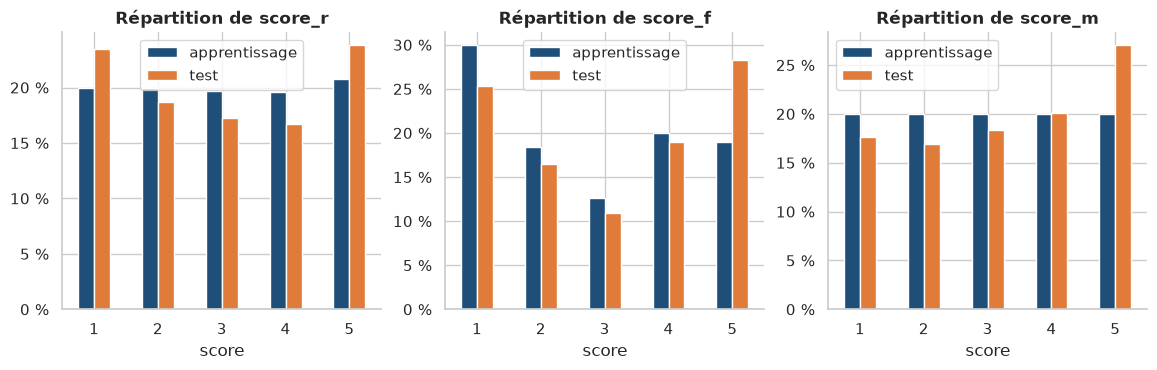

In [5]:
rfm = features.scores_rfm(clients, seuils)

# Répartition des scores : 20 % par score en apprentissage pour R et M (par construction) ; et en test ?
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, s in zip(axes, ["score_r", "score_f", "score_m"]):
    pd.crosstab(rfm[s], rfm["periode"], normalize="columns").plot.bar(ax=ax, color=[cfg.BLEU, cfg.ORANGE], rot=0)
    ax.set_title(f"Répartition de {s}"); cfg.format_pourcent(ax); ax.set_xlabel("score"); ax.legend(title="")
montrer("DM01_1_scores")

> **Lecture.** En apprentissage, R et M sont répartis à 20 % par score, comme voulu. La fréquence ne peut pas l'être : 30 % des clients n'ont qu'une commande (score F = 1). En 2025 (test), avec les **mêmes seuils**, les scores extrêmes augmentent (F = 5 : 28 % contre 19 %, M = 5 : 27 %) : l'historique des clients s'allonge, car les données commencent en 2023 ; la fréquence et le montant **cumulés** grossissent donc mécaniquement. **Pour le ML :** c'est une dérive connue et explicable ; le modèle devra aussi utiliser des variables sur une fenêtre fixe (`nb_commandes_90j`), insensibles à la durée d'historique.

## 4. Les segments

Les segments sont définis par des règles simples sur R et F (le montant M sert ensuite à décrire leur valeur). Ces règles sont dans `features._segment()` :

| Segment | Règle | Portrait |
|---|---|---|
| **Champions** | R ≥ 4 et F ≥ 4 | achètent souvent et récemment |
| **Fidèles** | R = 3 et F ≥ 4 | achètent souvent, un peu moins récemment |
| **Fidèles potentiels** | R ≥ 4 et F = 2 ou 3 | récents, déjà revenus une ou deux fois |
| **Nouveaux** | R ≥ 4 et F = 1 | une seule commande, toute récente |
| **À surveiller** | R = 3 et F ≤ 3 | ni récents ni fréquents |
| **À risque** | R ≤ 2 et F ≥ 4 | anciens bons clients qui ne reviennent plus |
| **Hibernants** | R ≤ 2 et F = 2 ou 3 | peu fréquents et absents depuis longtemps |
| **Perdus** | R ≤ 2 et F = 1 | une commande, il y a longtemps |

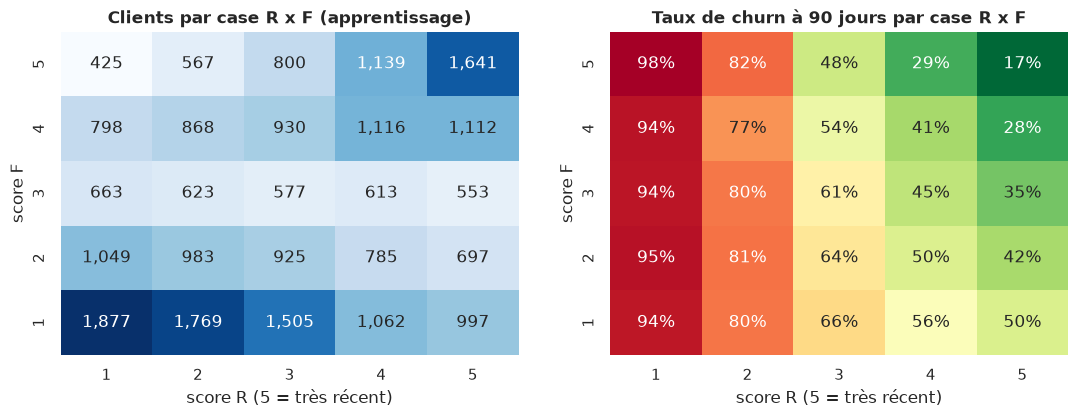

In [6]:
# Carte R x F : nombre de photos de clients (apprentissage) dans chaque case
app_rfm = rfm[rfm["periode"] == "apprentissage"]
carte = pd.crosstab(app_rfm["score_f"], app_rfm["score_r"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.heatmap(carte.sort_index(ascending=False), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Clients par case R x F (apprentissage)"); axes[0].set_xlabel("score R (5 = très récent)"); axes[0].set_ylabel("score F")

taux = app_rfm.pivot_table(index="score_f", columns="score_r", values="churn", aggfunc="mean")
sns.heatmap(taux.sort_index(ascending=False), annot=True, fmt=".0%", cmap="RdYlGn_r", cbar=False, ax=axes[1])
axes[1].set_title("Taux de churn à 90 jours par case R x F"); axes[1].set_xlabel("score R (5 = très récent)"); axes[1].set_ylabel("score F")
montrer("DM01_2_carte_RF")

> **Lecture.** La **récence domine** : quand le client n'a pas commandé depuis plus de 198 jours (R = 1), le churn dépasse 94 % quelle que soit sa fréquence. À récence égale, la fréquence protège : pour les clients très récents (R = 5), le churn passe de 50 % (une commande) à **17 %** (7 commandes et plus). Les cases les plus peuplées sont les clients à une seule commande (F = 1), surtout anciens.

## 5. Valeur des segments

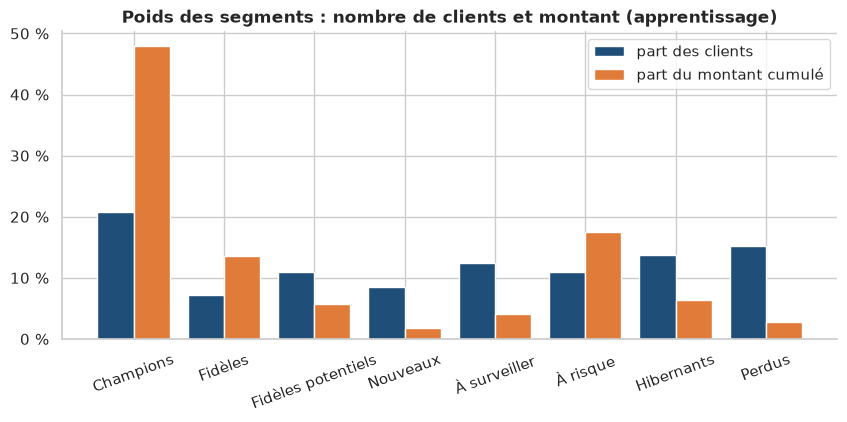

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.dm01_profil_segments                          8 lignes


,photos,recence_mediane_j,frequence_mediane,montant_median_ttc,panier_moyen_ttc,montant_total_ttc,part_clients,part_montant
segment_rfm,,,,,,,,
Champions,5008,19.000,7.000,1 356.330,193.553,11 104 681.950,0.208,0.480
Fidèles,1730,75.000,6.000,1 127.250,177.415,3 157 487.670,0.072,0.137
Fidèles potentiels,2648,23.000,2.000,288.950,132.952,1 326 391.780,0.110,0.057
Nouveaux,2059,22.000,1.000,84.800,101.900,427 455.770,0.086,0.018
À surveiller,3007,77.000,1.000,159.800,118.800,950 934.275,0.125,0.041
À risque,2658,188.000,5.000,940.250,173.000,4 036 029.595,0.110,0.174
Hibernants,3318,203.000,2.000,258.160,128.067,1 484 353.400,0.138,0.064
Perdus,3646,202.000,1.000,80.575,100.420,644 304.285,0.151,0.028


In [7]:
app_rfm = rfm[rfm["periode"] == "apprentissage"]
profil = app_rfm.groupby("segment_rfm", observed=True).agg(
    photos=("client_sk", "size"), recence_mediane_j=("recence_j", "median"), frequence_mediane=("frequence", "median"),
    montant_median_ttc=("montant_reconnu_ttc", "median"), panier_moyen_ttc=("panier_moyen_ttc", "median"),
    montant_total_ttc=("montant_reconnu_ttc", "sum"))
profil["part_clients"] = profil["photos"] / profil["photos"].sum()
profil["part_montant"] = profil["montant_total_ttc"] / profil["montant_total_ttc"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(profil))
ax.bar(x - 0.2, profil["part_clients"], width=0.4, color=cfg.BLEU, label="part des clients")
ax.bar(x + 0.2, profil["part_montant"], width=0.4, color=cfg.ORANGE, label="part du montant cumulé")
ax.set_xticks(x, profil.index, rotation=20); cfg.format_pourcent(ax); ax.legend()
ax.set_title("Poids des segments : nombre de clients et montant (apprentissage)")
montrer("DM01_3_valeur_segments")
cfg.exporter_table(profil, "DM01_profil_segments")
profil

> **Lecture.** Les **Champions** sont 21 % des clients mais **48 % du montant** cumulé. Avec les Fidèles et les clients **À risque**, trois segments (39 % des clients) portent **79 % du montant**. Le segment À risque pèse 17 % du montant pour 11 % des clients : ce sont d'anciens bons clients, la priorité de toute action de reconquête. À l'inverse, Nouveaux et Perdus (24 % des clients) ne font que 5 % du montant.

## 6. Les segments expliquent-ils le churn ? (validation pour le ML)

Si le segment est une bonne variable pour le modèle de churn, le taux de churn doit être **très différent d'un segment à l'autre**, et ces écarts doivent **rester les mêmes en 2025** (test), avec les seuils appris sur 2023-2024.

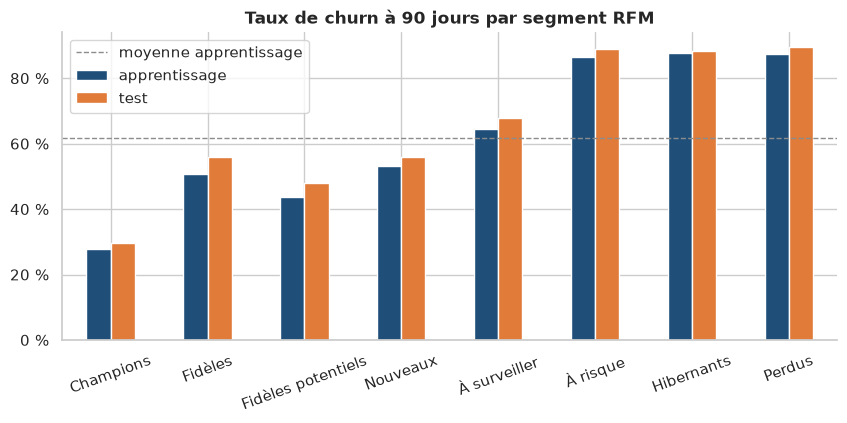

  ✔ ana.dm01_churn_par_segment                        8 lignes


periode,apprentissage,test,photos_test
segment_rfm,,,
Champions,0.278,0.297,4381
Fidèles,0.508,0.560,1534
Fidèles potentiels,0.437,0.480,1921
Nouveaux,0.532,0.561,1573
À surveiller,0.644,0.678,1820
À risque,0.866,0.890,3256
Hibernants,0.877,0.885,2416
Perdus,0.873,0.897,2513


In [8]:
churn_seg = rfm.pivot_table(index="segment_rfm", columns="periode", values="churn", aggfunc="mean", observed=True)
churn_seg["photos_test"] = rfm[rfm["periode"] == "test"]["segment_rfm"].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
churn_seg[["apprentissage", "test"]].plot.bar(ax=ax, color=[cfg.BLEU, cfg.ORANGE], rot=20)
ax.axhline(rfm.loc[rfm["periode"] == "apprentissage", "churn"].mean(), color=cfg.GRIS, ls="--", lw=1, label="moyenne apprentissage")
ax.set_title("Taux de churn à 90 jours par segment RFM"); cfg.format_pourcent(ax); ax.set_xlabel(""); ax.legend()
montrer("DM01_4_churn_segments")
cfg.exporter_table(churn_seg, "DM01_churn_par_segment")
churn_seg

> **Lecture.** Le taux de churn va de **28 %** (Champions) à **87-88 %** (À risque, Hibernants, Perdus) en apprentissage, et l'ordre des segments est **exactement le même en 2025** (de 30 % à 90 %), avec 2 à 5 points de plus partout (le churn moyen passe de 61,7 % à 64,3 %). **Pour le ML :** `segment_rfm` est une variable très discriminante et stable dans le temps, sans fuite (seuils appris sur 2023-2024). Attention : elle résume la récence et la fréquence, déjà présentes dans la table ; le modèle de churn mesurera ce qu'elle apporte en plus.

## 7. Migrations entre segments d'un trimestre à l'autre

Pour chaque client photographié à une fin de trimestre, où se trouve-t-il au trimestre suivant ? « Inactif » = il n'est plus client actif (aucune commande depuis 365 jours). On utilise les photos d'apprentissage.

In [ ]:
dates = sorted(app_rfm["date_observation"].unique())               # trimestres consécutifs de l'apprentissage
suivante = {d: dates[i + 1] for i, d in enumerate(dates[:-1])}
dep = app_rfm[app_rfm["date_observation"].isin(list(suivante))][["client_sk", "date_observation", "segment_rfm"]].copy()
dep["date_suivante"] = dep["date_observation"].map(suivante)
arr = rfm[["client_sk", "date_observation", "segment_rfm"]].rename(columns={"date_observation": "date_suivante", "segment_rfm": "segment_suivant"})
mig = dep.merge(arr, on=["client_sk", "date_suivante"], how="left")
mig["segment_suivant"] = mig["segment_suivant"].astype(object).fillna("Inactif")   # absent = plus client actif
ordre = features.ORDRE_SEGMENTS + ["Inactif"]
matrice = pd.crosstab(mig["segment_rfm"], mig["segment_suivant"], normalize="index").reindex(columns=ordre, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(matrice, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Segment au trimestre suivant (part des clients de chaque segment de départ)")
ax.set_xlabel("segment au trimestre suivant"); ax.set_ylabel("segment de départ")
montrer("DM01_5_migrations")
cfg.exporter_table(matrice, "DM01_migrations")

> **Lecture.** Les segments bougent beaucoup d'un trimestre à l'autre. Les **Champions** restent Champions à 55 % mais 18 % basculent directement À risque. Le point critique est le segment **Fidèles** : **la moitié devient À risque** le trimestre suivant, 39 % redeviennent Champions. Pour les **Nouveaux**, 34 % deviennent Perdus, 23 % Fidèles potentiels et 11 % Champions : le trimestre qui suit la 1re commande décide de tout. Les clients À risque restent À risque à 68 % ; 12 % reviennent en Champions, 16 % sortent de la base active. **Pour l'action :** surveiller les Fidèles et les Nouveaux en priorité, c'est là que se joue la bascule.

## 8. Actions par segment

Les actions s'appuient sur la taille, la valeur et le risque de churn de chaque segment mesurés ci-dessus.

In [10]:
actions = {
    "Champions": "Fidéliser : avantages exclusifs, accès anticipé au Black Friday, programme de parrainage",
    "Fidèles": "Maintenir le lien : recommandations personnalisées, offres sur les catégories déjà achetées",
    "Fidèles potentiels": "Transformer en habitude : relance 3 à 5 semaines après la commande, 2e catégorie suggérée",
    "Nouveaux": "Réussir la 2e commande : relance avant 30 jours, livraison soignée de la 1re commande",
    "À surveiller": "Réactiver tôt : rappel des nouveautés, emailing (canal le plus rentable)",
    "À risque": "Reconquête prioritaire (forte valeur passée) : offre personnalisée, enquête de satisfaction (retards subis ?)",
    "Hibernants": "Relance à faible coût : emailing, coupon ciblé uniquement si rentable",
    "Perdus": "Pas d'investissement individuel : campagnes générales seulement",
}
synth = churn_seg[["apprentissage", "test"]].rename(columns={"apprentissage": "churn_apprentissage", "test": "churn_test"})
synth = profil[["part_clients", "part_montant", "montant_median_ttc"]].join(synth)
synth["action_recommandee"] = synth.index.map(actions)
cfg.exporter_table(synth, "DM01_actions_segments")
synth

  ✔ ana.dm01_actions_segments                         8 lignes


,part_clients,part_montant,montant_median_ttc,churn_apprentissage,churn_test,action_recommandee
segment_rfm,,,,,,
Champions,0.208,0.480,1 356.330,0.278,0.297,"Fidéliser : avantages exclusifs, accès anticip..."
Fidèles,0.072,0.137,1 127.250,0.508,0.560,Maintenir le lien : recommandations personnali...
Fidèles potentiels,0.110,0.057,288.950,0.437,0.480,Transformer en habitude : relance 3 à 5 semain...
Nouveaux,0.086,0.018,84.800,0.532,0.561,Réussir la 2e commande : relance avant 30 jour...
À surveiller,0.125,0.041,159.800,0.644,0.678,"Réactiver tôt : rappel des nouveautés, emailin..."
À risque,0.110,0.174,940.250,0.866,0.890,Reconquête prioritaire (forte valeur passée) :...
Hibernants,0.138,0.064,258.160,0.877,0.885,"Relance à faible coût : emailing, coupon ciblé..."
Perdus,0.151,0.028,80.575,0.873,0.897,Pas d'investissement individuel : campagnes gé...


## 9. Sauvegarde : la variable « segment » pour le churn

On enregistre une ligne par client et par date d'observation : scores R, F, M, code RFM et segment.

In [11]:
segments = rfm[["client_sk", "date_observation", "periode", "score_r", "score_f", "score_m", "code_rfm", "segment_rfm"]].copy()
segments["segment_rfm"] = segments["segment_rfm"].astype(str)
features.sauvegarder(segments, "segments_rfm")

# Vérification : le ML retrouve bien le segment de chaque photo de client
essai = features.ajouter_segment_rfm(clients)
print("Photos sans segment :", int(essai["segment_rfm"].isna().sum()), "sur", len(essai))

  segments_rfm             43 488 lignes x  8 colonnes -> segments_rfm.parquet


  ✔ ana.dm_segments_rfm                          43 488 lignes
Photos sans segment : 0 sur 43488


## 10. Synthèse

> **Lecture.** La segmentation RFM classe les clients en **8 segments** compréhensibles, avec des seuils appris sur 2023-2024 et enregistrés (`06_Exports/Modeles/rfm_seuils.json`). Elle est **utile** (le churn va de 28 % à 88 % selon le segment), **stable** (même ordre en 2025) et **actionnable** (une action par segment, priorité aux clients À risque et aux Fidèles qui basculent). Sa variable `segment_rfm` est enregistrée pour chaque client et chaque date d'observation dans `05_Data/features/segments_rfm.parquet`, prête pour le modèle de churn.

In [12]:
chargement.fermer_connexion()

Connexion fermée.
